In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Определяем корневую папку проекта
BASE_DIR = Path.cwd().parent

# Путь к очищенному датасету
DATA_PATH = BASE_DIR / "data" / "processed" / "sms_clean.csv"

# Загружаем данные
df = pd.read_csv(DATA_PATH)

print("SMS GUARD — EDA")
print("Количество сообщений:", len(df))

print("\nПервые 5 записей:")
display(df.head())

print("\nИнформация о данных:")
df.info()

SMS GUARD — EDA
Количество сообщений: 5103

Первые 5 записей:


,id,text_raw,text_clean,label
0,1,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,0
1,2,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,3,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in <num> a wkly comp to win fa cup ...,1
3,4,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,0
4,5,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,0



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5103 entries, 0 to 5102
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          5103 non-null   int64 
 1   text_raw    5103 non-null   object
 2   text_clean  5103 non-null   object
 3   label       5103 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 159.6+ KB


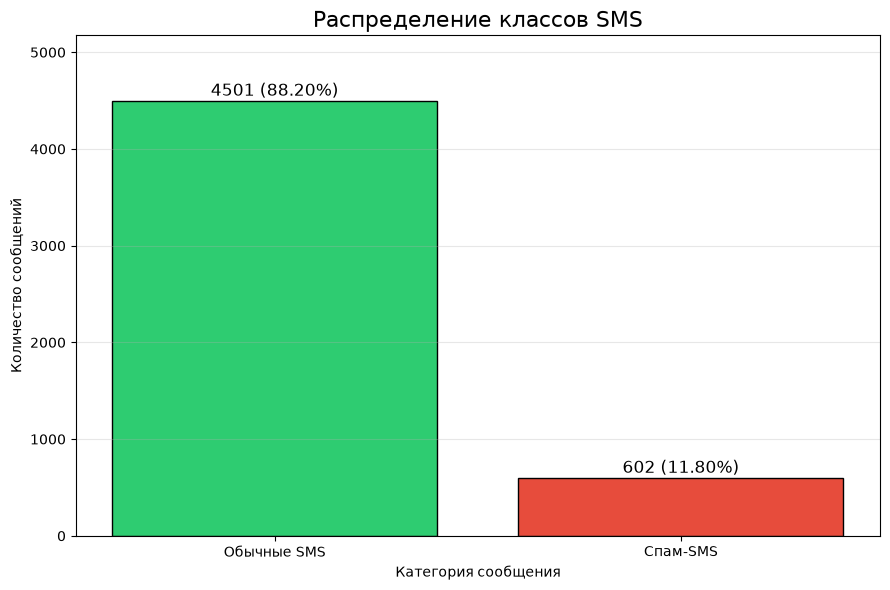

График успешно сохранён!


In [2]:
# Подсчитываем количество сообщений
class_counts = df["label"].value_counts().reindex(
    [0, 1], fill_value=0
)

# Названия категорий
labels = ["Обычные SMS", "Спам-SMS"]

# Цвета
colors = ["#2ecc71", "#e74c3c"]

# Создаём график
plt.figure(figsize=(9, 6))

bars = plt.bar(
    labels,
    class_counts.values,
    color=colors,
    edgecolor="black"
)

# Заголовок
plt.title(
    "Распределение классов SMS",
    fontsize=16
)

# Подписи осей
plt.xlabel("Категория сообщения")
plt.ylabel("Количество сообщений")

# Добавляем количество и процент
total = class_counts.sum()

for bar, count in zip(bars, class_counts.values):

    percentage = count / total * 100

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{count} ({percentage:.2f}%)",
        ha="center",
        fontsize=12
    )

plt.ylim(0, max(class_counts.values) * 1.15)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Сохраняем график
FIGURES_DIR = BASE_DIR / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "05_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("График успешно сохранён!")

In [3]:
# ГРАФИК №2 — АНАЛИЗ ДЛИНЫ SMS


# Подсчитываем длину исходных сообщений
df["char_length"] = df["text_raw"].fillna("").str.len()

# Подсчитываем количество слов
df["word_count"] = (
    df["text_raw"]
    .fillna("")
    .str.split()
    .str.len()
)

print("=== АНАЛИЗ ДЛИНЫ SMS ===")

# Группируем по классам
length_stats = df.groupby("label").agg(
    average_chars=("char_length", "mean"),
    median_chars=("char_length", "median"),
    average_words=("word_count", "mean"),
    median_words=("word_count", "median"),
    max_chars=("char_length", "max")
)

length_stats.index = [
    "Обычные SMS",
    "Спам-SMS"
]

# Округляем результаты
length_stats = length_stats.round(2)

display(length_stats)

=== АНАЛИЗ ДЛИНЫ SMS ===


,average_chars,median_chars,average_words,median_words,max_chars
Обычные SMS,71.10,53.0,14.28,11.0,910
Спам-SMS,137.78,149.0,23.80,25.0,223


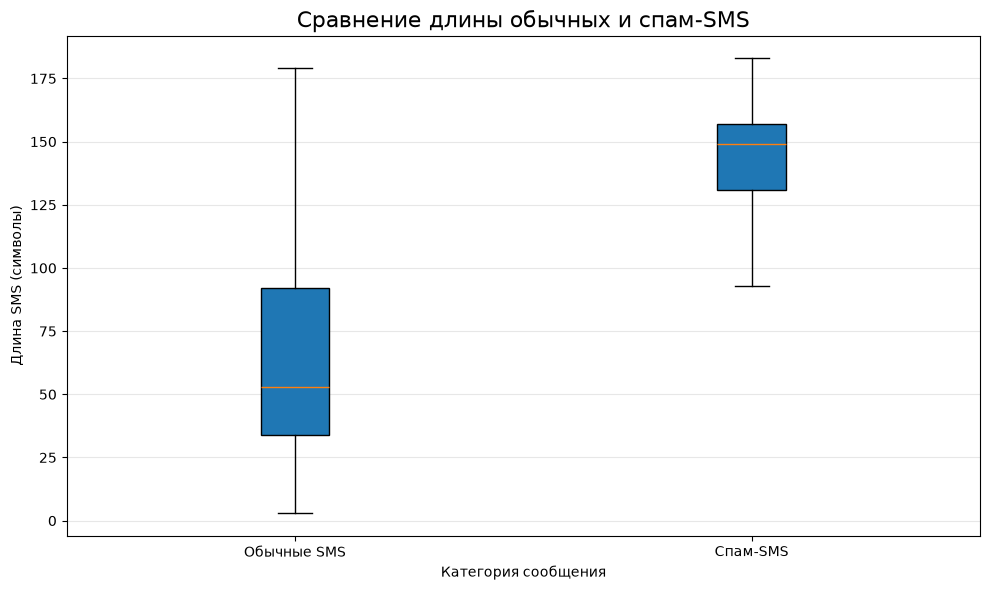

График длины SMS успешно сохранён!


In [4]:
# ==============================================
# РАСПРЕДЕЛЕНИЕ ДЛИНЫ SMS В СИМВОЛАХ
# ==============================================

# Разделяем данные по классам
normal_sms = df[df["label"] == 0]["char_length"]
spam_sms = df[df["label"] == 1]["char_length"]

# Создаём график
plt.figure(figsize=(10, 6))

plt.boxplot(
    [normal_sms, spam_sms],
    tick_labels=["Обычные SMS", "Спам-SMS"],
    patch_artist=True,
    showfliers=False
)

plt.title(
    "Сравнение длины обычных и спам-SMS",
    fontsize=16
)

plt.xlabel("Категория сообщения")
plt.ylabel("Длина SMS (символы)")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Сохраняем
plt.savefig(
    FIGURES_DIR / "05_sms_length_characters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("График длины SMS успешно сохранён!")

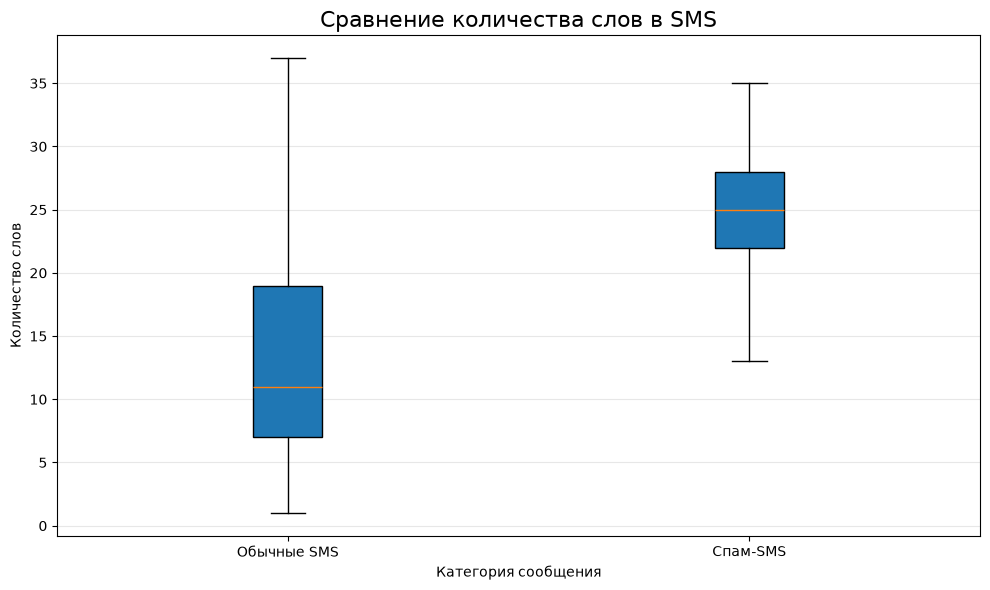

График количества слов успешно сохранён!


In [5]:
# ==============================================
# РАСПРЕДЕЛЕНИЕ КОЛИЧЕСТВА СЛОВ В SMS
# ==============================================

normal_words = df[df["label"] == 0]["word_count"]
spam_words = df[df["label"] == 1]["word_count"]

plt.figure(figsize=(10, 6))

plt.boxplot(
    [normal_words, spam_words],
    tick_labels=["Обычные SMS", "Спам-SMS"],
    patch_artist=True,
    showfliers=False
)

plt.title(
    "Сравнение количества слов в SMS",
    fontsize=16
)

plt.xlabel("Категория сообщения")
plt.ylabel("Количество слов")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_sms_length_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("График количества слов успешно сохранён!")


ТОП-20 СЛОВ: Обычные SMS


,Слово,Частота
3789,num,816
2340,gt,287
3274,lt,286
2925,just,282
3851,ok,251
3190,ll,231
2283,got,227
3006,know,226
3146,like,224
2266,good,217


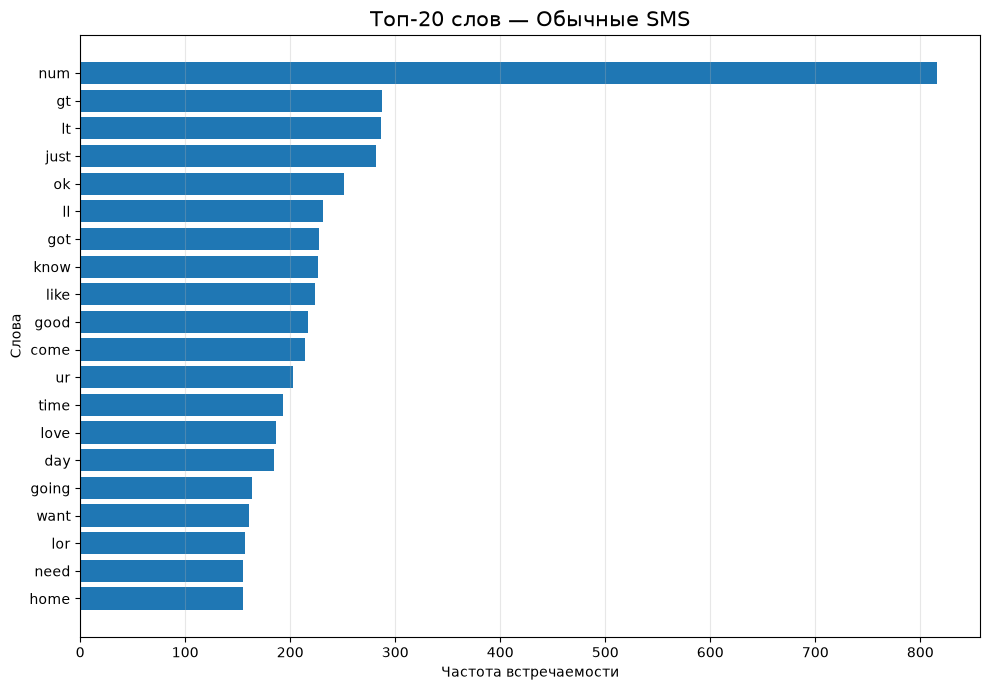


ТОП-20 СЛОВ: Спам-SMS


,Слово,Частота
957,num,970
1022,phone,376
885,money,233
513,free,181
1524,txt,126
1560,ur,114
1368,stop,110
1444,text,104
877,mobile,100
1174,reply,91


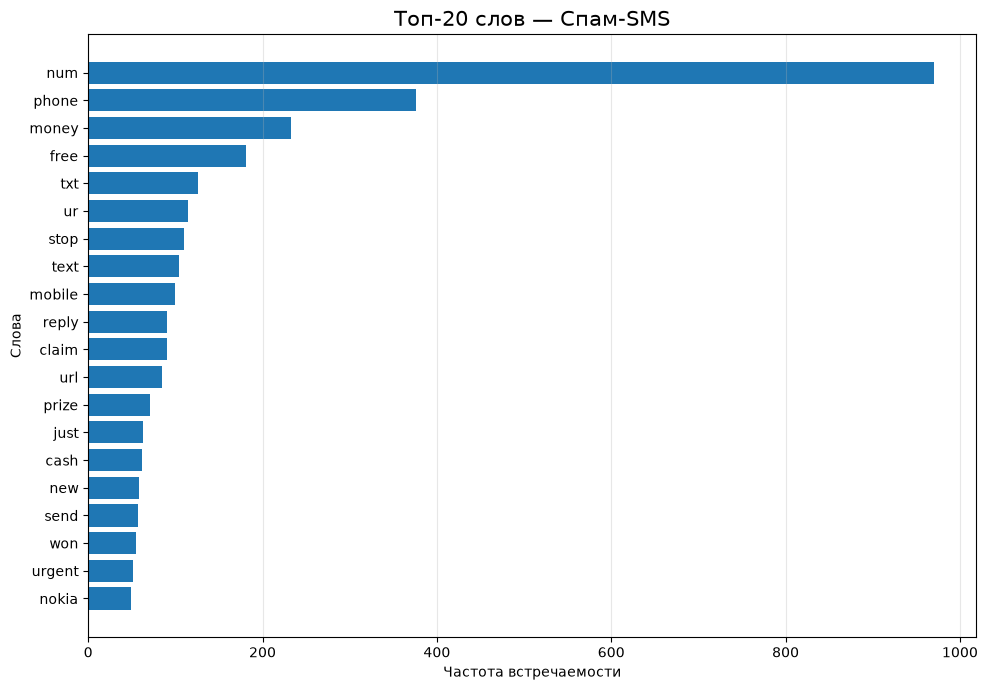


Анализ топ-20 слов завершён!


In [6]:
# ==========================================
# ГРАФИК №3 — ТОП-20 СЛОВ В SMS
# ==========================================

from sklearn.feature_extraction.text import CountVectorizer

# Анализируем каждый класс отдельно
categories = {
    0: "Обычные SMS",
    1: "Спам-SMS"
}

for label, category_name in categories.items():

    # Выбираем сообщения определённого класса
    texts = df[df["label"] == label]["text_clean"].fillna("")

    # Векторизатор для подсчёта слов
    vectorizer = CountVectorizer(
        stop_words="english",
        token_pattern=r"(?u)\b[a-z]{2,}\b"
    )

    # Подсчитываем частоты
    X = vectorizer.fit_transform(texts)

    words = vectorizer.get_feature_names_out()

    frequencies = X.sum(axis=0).A1

    # Создаём таблицу
    word_freq = pd.DataFrame({
        "Слово": words,
        "Частота": frequencies
    })

    # Выбираем 20 самых частых слов
    top20 = word_freq.sort_values(
        "Частота",
        ascending=False
    ).head(20)

    print(f"\nТОП-20 СЛОВ: {category_name}")

    display(top20)

    # Строим график
    plt.figure(figsize=(10, 7))

    plt.barh(
        top20["Слово"][::-1],
        top20["Частота"][::-1]
    )

    plt.title(
        f"Топ-20 слов — {category_name}",
        fontsize=15
    )

    plt.xlabel("Частота встречаемости")
    plt.ylabel("Слова")

    plt.grid(axis="x", alpha=0.3)

    plt.tight_layout()

    # Сохраняем изображения
    filename = (
        "05_top20_normal.png"
        if label == 0
        else "05_top20_spam.png"
    )

    plt.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nАнализ топ-20 слов завершён!")

АНАЛИЗ БИГРАММ: Обычные SMS

ТОП-20 БИГРАММ: Обычные SMS


,Биграмма,Частота
10654,let know,40
7127,good morning,24
4716,don know,22
13352,new year,21
9743,just got,20
14339,ok lor,18
21716,wat time,18
8453,hi hi,18
7132,good night,17
7998,happy new,17


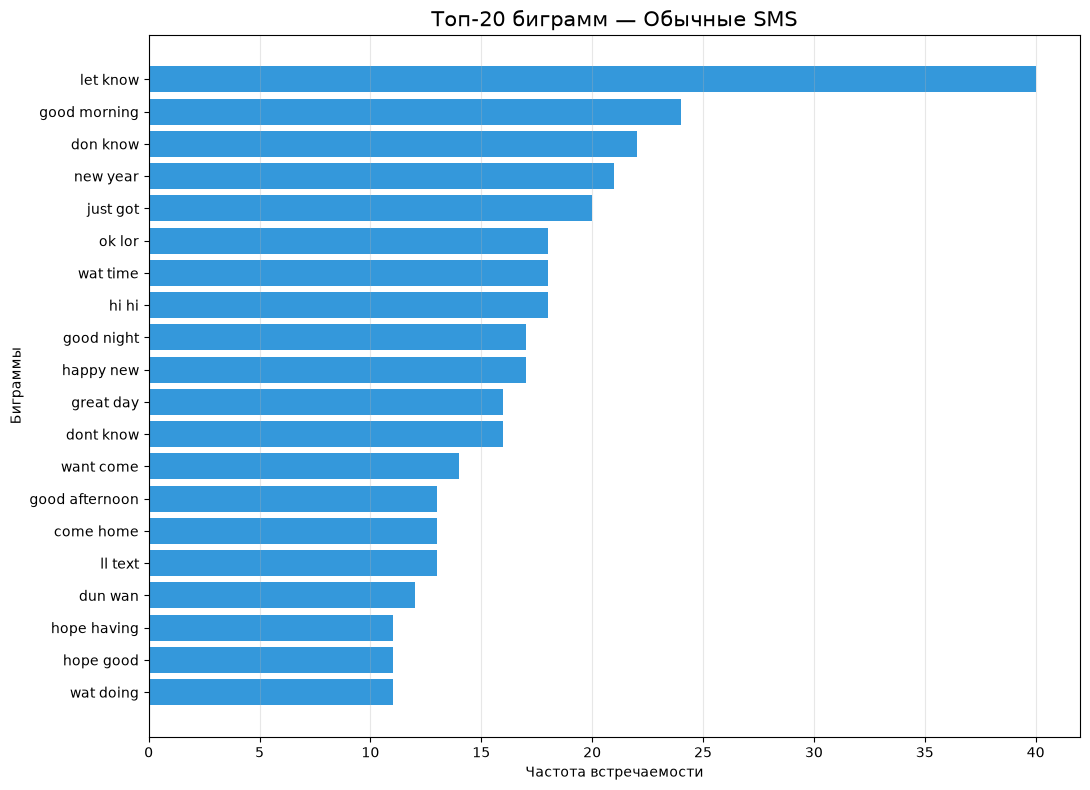

АНАЛИЗ БИГРАММ: Спам-SMS

ТОП-20 БИГРАММ: Спам-SMS


,Биграмма,Частота
3339,send stop,19
2897,po box,19
2980,prize guaranteed,17
3989,txt stop,16
4129,urgent mobile,15
139,await collection,15
1628,land line,13
888,draw shows,13
757,dating service,13
3933,trying contact,13


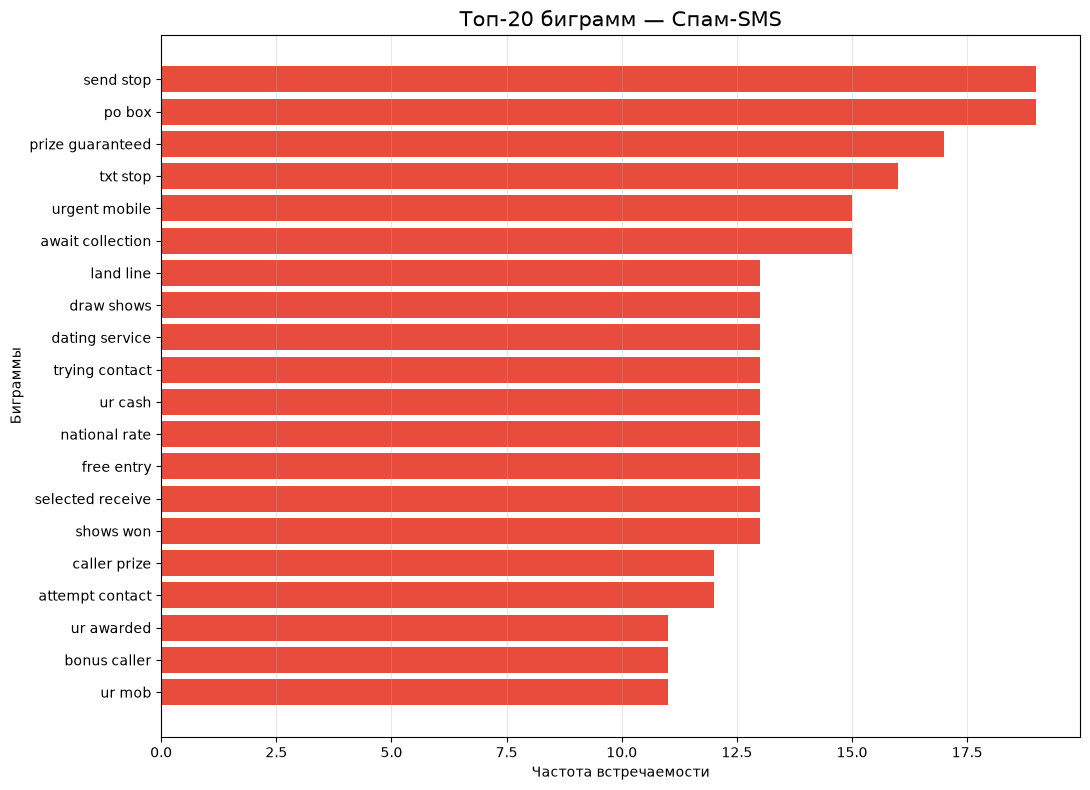


Анализ биграмм успешно завершён!


In [7]:
# ==============================================
# АНАЛИЗ ТОП-20 БИГРАММ
# ==============================================

from sklearn.feature_extraction.text import CountVectorizer

import pandas as pd
import matplotlib.pyplot as plt

# Категории сообщений
categories = {
    0: "Обычные SMS",
    1: "Спам-SMS"
}

# Служебные токены исключаем из рейтинга
excluded_tokens = {
    "num", "phone", "money",
    "url", "email", "gt", "lt"
}

for label, category_name in categories.items():

    print("=" * 50)
    print(f"АНАЛИЗ БИГРАММ: {category_name}")
    print("=" * 50)

    # Выбираем сообщения нужного класса
    texts = df[
        df["label"] == label
    ]["text_clean"].fillna("")

    # Создаём векторизатор биграмм
    vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=(2, 2),
        token_pattern=r"(?u)\b[a-z]{2,}\b"
    )

    # Подсчёт частот
    X = vectorizer.fit_transform(texts)

    bigrams = vectorizer.get_feature_names_out()

    frequencies = X.sum(axis=0).A1

    # Создаём таблицу частот
    bigram_df = pd.DataFrame({
        "Биграмма": bigrams,
        "Частота": frequencies
    })

    # Убираем биграммы со служебными токенами
    mask = bigram_df["Биграмма"].apply(
        lambda phrase: not any(
            word in excluded_tokens
            for word in phrase.split()
        )
    )

    bigram_df = bigram_df[mask]

    # Топ-20 биграмм
    top20 = bigram_df.sort_values(
        "Частота",
        ascending=False
    ).head(20)

    print(f"\nТОП-20 БИГРАММ: {category_name}")

    display(top20)

    # Строим график
    plt.figure(figsize=(11, 8))

    plt.barh(
        top20["Биграмма"][::-1],
        top20["Частота"][::-1],
        color="#3498db" if label == 0 else "#e74c3c"
    )

    plt.title(
        f"Топ-20 биграмм — {category_name}",
        fontsize=15
    )

    plt.xlabel("Частота встречаемости")
    plt.ylabel("Биграммы")

    plt.grid(axis="x", alpha=0.3)

    plt.tight_layout()

    # Сохраняем график
    filename = (
        "05_bigrams_normal.png"
        if label == 0
        else "05_bigrams_spam.png"
    )

    plt.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nАнализ биграмм успешно завершён!")

In [8]:
# ==========================================
# АНАЛИЗ ПОДОЗРИТЕЛЬНЫХ ПРИЗНАКОВ SMS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# Признаки для анализа
features = {
    "URL": "<url>",
    "Телефон": "<phone>",
    "Денежная сумма": "<money>",
    "Восклицательный знак": "!"
}

categories = {
    0: "Обычные SMS",
    1: "Спам-SMS"
}

results = []

for label, category_name in categories.items():

    # Выбираем сообщения нужного класса
    texts = df[
        df["label"] == label
    ]["text_clean"].fillna("")

    total = len(texts)

    for feature_name, token in features.items():

        # Определяем наличие признака
        count = texts.str.contains(
            token,
            regex=False
        ).sum()

        # Рассчитываем процент
        percentage = count / total * 100

        results.append({
            "Категория": category_name,
            "Признак": feature_name,
            "Количество": int(count),
            "Процент": round(percentage, 2)
        })

# Создаём таблицу
features_df = pd.DataFrame(results)

print("=== АНАЛИЗ ПОДОЗРИТЕЛЬНЫХ ПРИЗНАКОВ ===")

display(features_df)

=== АНАЛИЗ ПОДОЗРИТЕЛЬНЫХ ПРИЗНАКОВ ===


,Категория,Признак,Количество,Процент
0,Обычные SMS,URL,1,0.02
1,Обычные SMS,Телефон,1,0.02
2,Обычные SMS,Денежная сумма,11,0.24
3,Обычные SMS,Восклицательный знак,530,11.78
4,Спам-SMS,URL,85,14.12
5,Спам-SMS,Телефон,309,51.33
6,Спам-SMS,Денежная сумма,186,30.90
7,Спам-SMS,Восклицательный знак,281,46.68


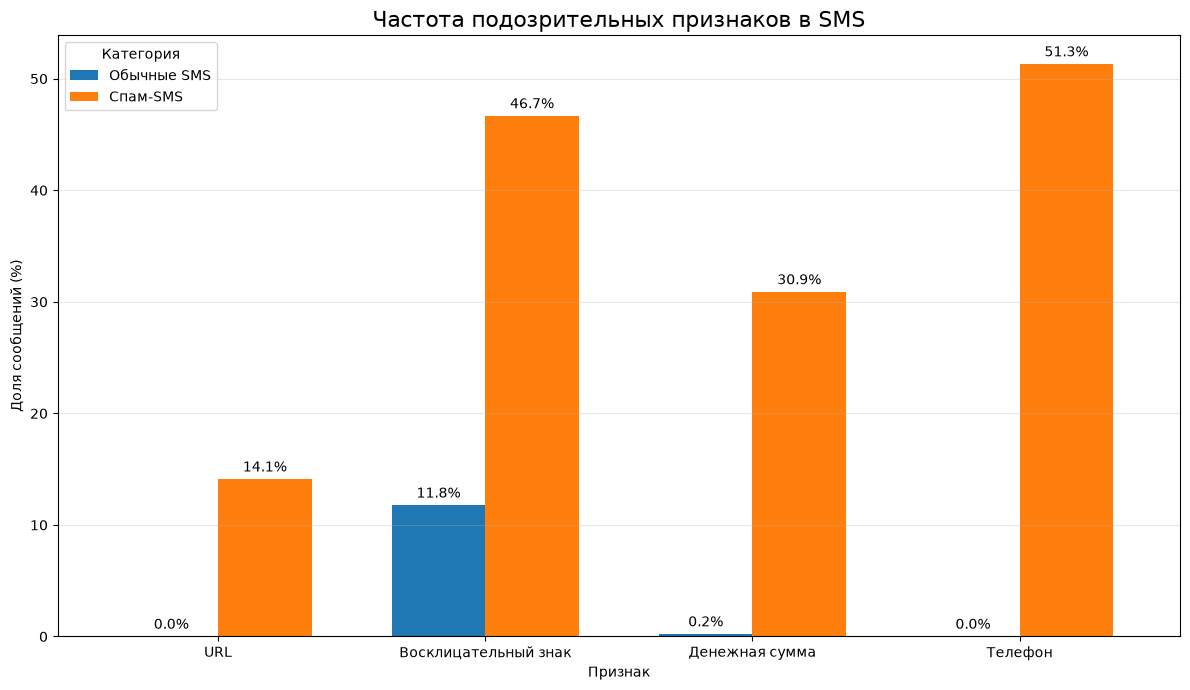

График подозрительных признаков сохранён!


In [9]:
# ==========================================
# ГРАФИК ПОДОЗРИТЕЛЬНЫХ ПРИЗНАКОВ SMS
# ==========================================

# Преобразуем результаты для графика
pivot_df = features_df.pivot(
    index="Признак",
    columns="Категория",
    values="Процент"
)

# Упорядочиваем категории
pivot_df = pivot_df[
    ["Обычные SMS", "Спам-SMS"]
]

# Создаём график
ax = pivot_df.plot(
    kind="bar",
    figsize=(12, 7),
    width=0.7
)

plt.title(
    "Частота подозрительных признаков в SMS",
    fontsize=16
)

plt.xlabel("Признак")
plt.ylabel("Доля сообщений (%)")

plt.xticks(rotation=0)

plt.legend(title="Категория")

plt.grid(
    axis="y",
    alpha=0.3
)

# Добавляем подписи процентов
for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()

# Сохраняем график
plt.savefig(
    FIGURES_DIR / "05_suspicious_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("График подозрительных признаков сохранён!")

# Итоговые выводы исследовательского анализа SMS

## 1. Общая характеристика данных

В ходе выполнения исследовательского анализа был изучен очищенный набор данных SMS Spam Collection.

После предварительной обработки исходных 5574 сообщений осталось 5103 уникальных SMS, из которых:

* 4501 сообщение (88,20%) относится к категории обычных SMS;
* 602 сообщения (11,80%) относится к категории спама.

Анализ выполнен с использованием Python, Pandas, Matplotlib и Scikit-learn.

## 2. Основные результаты исследования

**Вывод 1. Набор данных имеет выраженный дисбаланс классов.**

Обычные сообщения составляют 88,20% датасета, тогда как спам — только 11,80%.

Следовательно, при обучении моделей необходимо учитывать дисбаланс классов. Для этого планируется использовать стратифицированное разбиение и метрики Precision, Recall и F1-score.

**Вывод 2. Спам-сообщения в среднем длиннее обычных.**

Средняя длина обычных SMS составляет 71,10 символа, а спам-SMS — 137,78 символа.

Таким образом, спам-сообщения в среднем длиннее примерно в 1,94 раза.

Среднее количество слов также различается: 14,28 слова в обычных сообщениях и 23,80 слова в спаме.

Длина сообщения может использоваться как дополнительный числовой признак при классификации.

**Вывод 3. Частотный анализ выявил различия в словарном составе сообщений.**

В обычных SMS часто встречаются слова:

`just` — 282 раза, `ok` — 251, `know` — 226, `good` — 217.

В спам-сообщениях часто используются слова:

`free` — 181 раз, `claim` — 90, `prize` — 71, `cash` — 62, `urgent` — 52.

Это показывает, что спам чаще содержит слова, связанные с вознаграждением, призами и побуждением к действиям.

**Вывод 4. Биграммы позволяют обнаруживать характерные словосочетания.**

В обычных сообщениях наиболее распространены сочетания:

`let know` — 40 раз, `good morning` — 24, `new year` — 21.

В спаме часто встречаются:

`prize guaranteed` — 17 раз, `urgent mobile` — 15, `free entry` — 13.

Полученные результаты подтверждают целесообразность использования словесных N-грамм при построении TF-IDF-признаков.

**Вывод 5. Интернет-ссылки значительно чаще обнаруживаются в спаме.**

Признак `<url>` присутствует в 85 спам-сообщениях (14,12%) и только в одном обычном сообщении (0,02%).

Это подтверждает полезность анализа ссылок как дополнительного компонента системы SMS Guard.

**Вывод 6. Телефонные номера и денежные суммы являются информативными признаками.**

Токен `<phone>` обнаружен в 309 спам-сообщениях (51,33%) и одном обычном сообщении (0,02%).

Токен `<money>` встречается в 186 спам-SMS (30,90%) и 11 обычных SMS (0,24%).

Следовательно, наличие телефонных номеров и денежных сумм может использоваться в модели как дополнительная информация.

**Вывод 7. Восклицательные знаки чаще встречаются в спам-сообщениях.**

Восклицательные знаки обнаружены в 281 спам-SMS (46,68%) и 530 обычных SMS (11,78%).

Это позволяет рассматривать наличие и количество восклицательных знаков как дополнительные признаки эмоционального давления.

## 3. Ограничения исследования

Исследование выполнено на англоязычном датасете SMS Spam Collection.

Категория spam включает не только потенциально мошеннические сообщения, но и нежелательные рекламные рассылки.

Поэтому результаты исследования нельзя напрямую распространять на все виды SMS-мошенничества.

Также наличие отдельных признаков зависит от качества предварительной обработки и распознавания телефонов, денежных сумм и URL.

Описательный анализ проведён до обучения моделей. Полученные результаты не должны использоваться для подбора параметров по будущей тестовой выборке.

## 4. Общий вывод

Проведённый исследовательский анализ показал, что обычные и спам-SMS имеют заметные различия по длине, словарному составу, частоте биграмм и наличию структурных признаков.

Наиболее перспективными признаками для дальнейшего исследования являются:

* TF-IDF-представление слов и N-грамм;
* длина сообщения и количество слов;
* наличие URL и телефонных номеров;
* наличие денежных сумм;
* количество восклицательных знаков.

Полученные результаты будут использованы при проектировании признакового пространства в задании №6.

Для объективной оценки качества будущих моделей данные будут разделены на обучающую, валидационную и тестовую выборки.

Окончательная полезность обнаруженных признаков будет проверяться экспериментально.
